In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

PROJECT_DIR = Path.cwd().parent
PROCESSED_DIR = PROJECT_DIR / "data" / "processed_224_pad_gray"
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

def load_split(name):
    with np.load(PROCESSED_DIR / f"{name}.npz") as data:
        X = data["images"].astype(np.float32) / 255.0
        y = data["labels"].astype(np.int64)
    return X, y

X_train, y_train = load_split("train")
X_val, y_val = load_split("validation")

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("TensorFlow:", tf.__version__)

Train: (4181, 224, 224) (4181,)
Validation: (1051, 224, 224) (1051,)
TensorFlow: 2.21.0


In [2]:
tf.keras.utils.set_random_seed(42)

cnn_model = keras.Sequential([
    keras.Input(shape=(224, 224, 1)),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc")
    ]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,993 (394.50 KB)

 Trainable params: 100,993 (394.50 KB)

 Non-trainable params: 0 (0.00 B)

In [3]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)
}

print("Class weights:", class_weights)

Class weights: {0: 1.9338575393154487, 1: 0.6743548387096774}


In [4]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=3,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        MODEL_DIR / "cnn_from_scratch.keras",
        monitor="val_auc",
        mode="max",
        save_best_only=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

# Add the channel dimension: (N, 224, 224) -> (N, 224, 224, 1)
X_train_cnn = X_train[..., np.newaxis]
X_val_cnn = X_val[..., np.newaxis]

history_cnn = cnn_model.fit(
    X_train_cnn,
    y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=10,
    batch_size=32,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 71s 537ms/step - accuracy: 0.5996 - auc: 0.6772 - loss: 0.6444 - val_accuracy: 0.7945 - val_auc: 0.8215 - val_loss: 0.4650 - learning_rate: 0.0010
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 77s 585ms/step - accuracy: 0.6936 - auc: 0.7534 - loss: 0.5925 - val_accuracy: 0.8030 - val_auc: 0.8296 - val_loss: 0.4401 - learning_rate: 0.0010
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 80s 610ms/step - accuracy: 0.7037 - auc: 0.7718 - loss: 0.5722 - val_accuracy: 0.8021 - val_auc: 0.8490 - val_loss: 0.4491 - learning_rate: 0.0010
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 79s 604ms/step - accuracy: 0.7364 - auc: 0.8076 - loss: 0.5385 - val_accuracy: 0.8506 - val_auc: 0.9019 - val_loss: 0.3579 - learning_rate: 0.0010
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 80s 612ms/step - accuracy: 0.7812 - auc: 0.8698 - loss: 0.4523 - val_accuracy: 0.8754 - val_auc: 0.9423 - val_loss: 0.2970 - learning_rate: 0.0010
Epoch 6/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 80s 614ms/step - accuracy

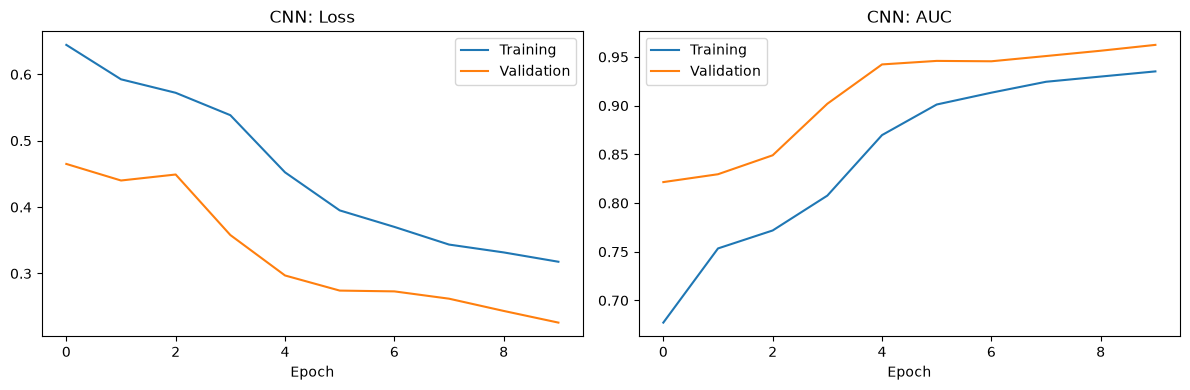

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_cnn.history["loss"], label="Training")
axes[0].plot(history_cnn.history["val_loss"], label="Validation")
axes[0].set_title("CNN: Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_cnn.history["auc"], label="Training")
axes[1].plot(history_cnn.history["val_auc"], label="Validation")
axes[1].set_title("CNN: AUC")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [6]:
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

best_cnn = keras.models.load_model(
    MODEL_DIR / "cnn_from_scratch.keras"
)

cnn_val_prob = best_cnn.predict(X_val_cnn, verbose=0).ravel()
cnn_val_pred = (cnn_val_prob >= 0.5).astype(int)

print("CNN validation AUC:",
      round(roc_auc_score(y_val, cnn_val_prob), 4))
print("CNN validation accuracy at 0.5:",
      round(accuracy_score(y_val, cnn_val_pred), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_val, cnn_val_pred, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_val,
    cnn_val_pred,
    labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))

CNN validation AUC: 0.9625
CNN validation accuracy at 0.5: 0.9058

Confusion matrix:
[[232  36]
 [ 63 720]]

Classification report:
              precision    recall  f1-score   support

      NORMAL       0.79      0.87      0.82       268
   PNEUMONIA       0.95      0.92      0.94       783

    accuracy                           0.91      1051
   macro avg       0.87      0.89      0.88      1051
weighted avg       0.91      0.91      0.91      1051



In [7]:
dense_model_for_comparison = keras.models.load_model(
    MODEL_DIR / "dense_baseline.keras"
)

dense_val_prob = dense_model_for_comparison.predict(
    X_val, verbose=0
).ravel()

In [8]:
comparison = pd.DataFrame([
    {
        "Model": "Dense baseline",
        "Validation AUC": roc_auc_score(y_val, dense_val_prob),
        "Accuracy at 0.5": accuracy_score(
            y_val, (dense_val_prob >= 0.5).astype(int)
        )
    },
    {
        "Model": "CNN from scratch",
        "Validation AUC": roc_auc_score(y_val, cnn_val_prob),
        "Accuracy at 0.5": accuracy_score(
            y_val, (cnn_val_prob >= 0.5).astype(int)
        )
    }
])

display(comparison.round(4))

,Model,Validation AUC,Accuracy at 0.5
0,Dense baseline,0.9830,0.9286
1,CNN from scratch,0.9625,0.9058


In [9]:
from sklearn.metrics import roc_curve
import numpy as np

def sensitivity_at_specificity(y_true, probabilities, target=0.95):
    fpr, tpr, thresholds = roc_curve(y_true, probabilities)
    specificity = 1 - fpr

    eligible = np.where(specificity >= target)[0]
    best_idx = eligible[np.argmax(tpr[eligible])]

    return {
        "threshold": round(float(thresholds[best_idx]), 4),
        "sensitivity": round(float(tpr[best_idx]), 4),
        "specificity": round(float(specificity[best_idx]), 4)
    }

print("Dense baseline:",
      sensitivity_at_specificity(y_val, dense_val_prob))

print("CNN:",
      sensitivity_at_specificity(y_val, cnn_val_prob))

Dense baseline: {'threshold': 0.835, 'sensitivity': 0.9183, 'specificity': 0.9552}
CNN: {'threshold': 0.7426, 'sensitivity': 0.8582, 'specificity': 0.9515}
